# 03 · Is the book for children? (`juvenile`)

**Label.** `juvenile = 1` when the book's catalogue record has a subject tag containing "juvenile" (the library's marker for books written for children / young readers). About 17% of the 5,600 books.

**Two tests.**
* **A. Without description:** all 5,600 books, using only the title, creator, year, pages (and, in one variant, genre flags).
* **B. With description:** the 3,152 books that have a usable description; compared with the same books *without* it.

**The subject tags are hidden from the model.** The label is made from them, so using them would just read the answer.

**Accuracy is misleading here.** 83% of the books are *not* juvenile, so "always say no" already scores about 83%. Judge by: **AUC** (ranking quality), **recall** (share of children's books found), **precision**, **F1**, and **balanced accuracy**, always next to the always-no baseline. The decision threshold is chosen on training data only.

The label is a cataloguer's tag: a missing tag does not prove a book is for adults, so some "errors" are really missing labels.

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "2")       # be gentle with the laptop
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display

SEED = 2026
QUICK = False            # True = smaller/faster run (fewer trees, 3 folds)
N_FOLDS = 3 if QUICK else 5
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 180, "display.max_columns", 40, "display.max_rows", 200)

def find(name):
    """Local repo (notebooks/ or repo root) or, in Google Colab, ask for an upload."""
    for base in [Path("../data"), Path("data"), Path(".")]:
        if (base / name).exists():
            return base / name
    try:
        from google.colab import files
        print("Upload", name); files.upload()
        return Path(name)
    except ImportError:
        raise FileNotFoundError(name + " not found: run from notebooks/ in the repo or put the file next to the notebook")

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, f1_score, recall_score, precision_score, balanced_accuracy_score,
                             accuracy_score, precision_recall_curve, confusion_matrix)

full = pd.read_csv(find("training_api.csv"), encoding="utf-8-sig")
withd = pd.read_csv(find("training_with_descriptions.csv"), encoding="utf-8-sig")
FLAGS = ["genre_science_fiction", "genre_fantasy", "genre_mystery_thriller"]
for d in (full, withd):
    d["title_creator"] = d["title"].fillna("") + " || " + d["first_creator"].fillna("")
    d["title_only"] = d["title"].fillna("")
    for c in FLAGS: d[c] = d[c].astype(int)
withd["description"] = withd["description"].fillna("")
for name, d in (("all books", full), ("books with description", withd)):
    print(f"{name}: {len(d)} books, juvenile = {d['juvenile'].mean():.1%} -> always-'no' accuracy = {1 - d['juvenile'].mean():.1%}")

all books: 5600 books, juvenile = 17.4% -> always-'no' accuracy = 82.6%
books with description: 3152 books, juvenile = 24.4% -> always-'no' accuracy = 75.6%


In [2]:
def make_pre(text_cols=("title_creator",), desc=False, nums=()):
    parts = []
    for c in text_cols:
        parts.append((c, TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), c))
    if desc:
        parts.append(("desc", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=6000, sublinear_tf=True, stop_words="english"), "description"))
    if nums:
        parts.append(("num", StandardScaler(), list(nums)))
    return ColumnTransformer(parts)

def model_zoo():
    return {
        "LogReg": lambda pre: Pipeline([("pre", pre), ("m", LogisticRegression(max_iter=3000, C=3, class_weight="balanced"))]),
        "LinearSVC": lambda pre: Pipeline([("pre", pre), ("m", LinearSVC(C=0.3, class_weight="balanced"))]),
        "HGB (on SVD of text)": lambda pre: Pipeline([("pre", pre), ("svd", TruncatedSVD(100 if not QUICK else 50, random_state=SEED)),
                                                       ("m", HistGradientBoostingClassifier(max_iter=120, learning_rate=0.06, class_weight="balanced", random_state=SEED))]),
    }
def score(m, X):
    return m.predict_proba(X)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(X)
def default_thr(m): return 0.5 if hasattr(m, "predict_proba") else 0.0

def best_threshold(y, s):
    p, r, t = precision_recall_curve(y, s); f = 2 * p * r / np.maximum(p + r, 1e-9)
    return t[np.argmax(f[:-1])]

def metrics(y, s, thr):
    pr = (s >= thr).astype(int)
    return {"AUC": roc_auc_score(y, s), "accuracy": accuracy_score(y, pr), "balanced acc": balanced_accuracy_score(y, pr),
            "recall (kids found)": recall_score(y, pr), "precision": precision_score(y, pr, zero_division=0), "F1": f1_score(y, pr),
            "baseline acc (always no)": 1 - y.mean()}

def evaluate(d, label, pre_fn, models=None):
    """Locked 15% test + 5-fold CV on the rest (grouped by work). Threshold chosen on the training pool's out-of-fold scores."""
    y = d["juvenile"].values
    pi, ti = next(StratifiedGroupKFold(7, shuffle=True, random_state=SEED).split(d, y, d["work_group"]))
    pool, test = d.iloc[pi].reset_index(drop=True), d.iloc[ti].reset_index(drop=True)
    yp, yt = pool["juvenile"].values, test["juvenile"].values
    rows, keep = [], {}
    for name, mk in model_zoo().items():
        if models and name not in models: continue
        oof = np.zeros(len(pool))
        for tr, te in StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED).split(pool, yp, pool["work_group"]):
            m = mk(pre_fn()).fit(pool.iloc[tr], yp[tr]); oof[te] = score(m, pool.iloc[te])
        thr = best_threshold(yp, oof)
        m = mk(pre_fn()).fit(pool, yp); st = score(m, test)
        cvm, tm = metrics(yp, oof, thr), metrics(yt, st, thr)
        rows.append({"data": label, "model": name, "CV AUC": cvm["AUC"], "CV F1": cvm["F1"], **{"TEST " + k: v for k, v in tm.items()}})
        keep[name] = (m, st, yt, thr, test)
    return pd.DataFrame(rows), keep
print("ready")

ready


## A. Without description (all 5,600 books)
Four variants, from least to most information. `+ genre flags` uses information derived from the same subject tags, so treat it as a different (easier) setting.

In [3]:
res, kept = [], {}
variants_A = {
    "A1 title only":                  lambda: make_pre(("title_only",)),
    "A2 title + creator":             lambda: make_pre(("title_creator",)),
    "A3 title + creator + year/pages": lambda: make_pre(("title_creator",), nums=["publication_year", "scanned_page_count"]),
    "A4 ... + genre flags":           lambda: make_pre(("title_creator",), nums=["publication_year", "scanned_page_count"] + FLAGS),
}
for label, pre_fn in variants_A.items():
    r, k = evaluate(full, label, pre_fn); res.append(r); kept[label] = k; print(label, "done", flush=True)
resA = pd.concat(res, ignore_index=True)
display(resA.round(3))

A1 title only done


A2 title + creator done


A3 title + creator + year/pages done


A4 ... + genre flags done


,data,model,CV AUC,CV F1,TEST AUC,TEST accuracy,TEST balanced acc,TEST recall (kids found),TEST precision,TEST F1,TEST baseline acc (always no)
0,A1 title only,LogReg,0.584,0.319,0.668,0.402,0.578,0.865,0.226,0.358,0.807
1,A1 title only,LinearSVC,0.582,0.318,0.665,0.395,0.573,0.865,0.224,0.355,0.807
2,A1 title only,HGB (on SVD of text),0.570,0.313,0.616,0.357,0.560,0.890,0.217,0.348,0.807
3,A2 title + creator,LogReg,0.695,0.386,0.756,0.706,0.693,0.671,0.360,0.468,0.807
4,A2 title + creator,LinearSVC,0.691,0.383,0.756,0.700,0.711,0.729,0.362,0.484,0.807
5,A2 title + creator,HGB (on SVD of text),0.654,0.354,0.673,0.620,0.622,0.626,0.282,0.389,0.807
6,A3 title + creator + year/pages,LogReg,0.741,0.425,0.793,0.715,0.732,0.761,0.381,0.508,0.807
7,A3 title + creator + year/pages,LinearSVC,0.736,0.419,0.792,0.697,0.724,0.768,0.365,0.495,0.807
8,A3 title + creator + year/pages,HGB (on SVD of text),0.741,0.419,0.779,0.653,0.694,0.761,0.328,0.458,0.807
9,A4 ... + genre flags,LogReg,0.764,0.443,0.792,0.736,0.724,0.703,0.396,0.507,0.807


## B. With description (the 3,152 books that have one)
Same books and same split for every row, so the with/without comparison is fair. `B1` is the no-description control.

In [4]:
res = []
variants_B = {
    "B1 title + creator (control, no description)": lambda: make_pre(("title_creator",)),
    "B2 title + creator + DESCRIPTION":             lambda: make_pre(("title_creator",), desc=True),
    "B3 description only":                           lambda: make_pre((), desc=True),
    "B4 all + year/pages":                           lambda: make_pre(("title_creator",), desc=True, nums=["publication_year", "scanned_page_count"]),
}
for label, pre_fn in variants_B.items():
    r, k = evaluate(withd, label, pre_fn); res.append(r); kept[label] = k; print(label, "done", flush=True)
resB = pd.concat(res, ignore_index=True)
display(resB.round(3))

B1 title + creator (control, no description) done


B2 title + creator + DESCRIPTION done


B3 description only done


B4 all + year/pages done


,data,model,CV AUC,CV F1,TEST AUC,TEST accuracy,TEST balanced acc,TEST recall (kids found),TEST precision,TEST F1,TEST baseline acc (always no)
0,"B1 title + creator (control, no description)",LogReg,0.638,0.440,0.706,0.556,0.644,0.802,0.308,0.445,0.778
1,"B1 title + creator (control, no description)",LinearSVC,0.637,0.440,0.703,0.552,0.641,0.802,0.306,0.443,0.778
2,"B1 title + creator (control, no description)",HGB (on SVD of text),0.621,0.427,0.624,0.499,0.586,0.743,0.271,0.397,0.778
3,B2 title + creator + DESCRIPTION,LogReg,0.770,0.539,0.814,0.721,0.722,0.723,0.424,0.535,0.778
4,B2 title + creator + DESCRIPTION,LinearSVC,0.762,0.533,0.811,0.708,0.731,0.772,0.415,0.540,0.778
5,B2 title + creator + DESCRIPTION,HGB (on SVD of text),0.773,0.539,0.780,0.743,0.690,0.594,0.441,0.506,0.778
6,B3 description only,LogReg,0.786,0.553,0.793,0.721,0.704,0.673,0.420,0.517,0.778
7,B3 description only,LinearSVC,0.782,0.552,0.788,0.719,0.713,0.703,0.420,0.526,0.778
8,B3 description only,HGB (on SVD of text),0.780,0.544,0.817,0.734,0.748,0.772,0.443,0.563,0.778
9,B4 all + year/pages,LogReg,0.796,0.573,0.824,0.765,0.739,0.693,0.479,0.567,0.778


## Best results, and how they compare with the targets

,data,model,CV AUC,TEST AUC,TEST accuracy,TEST balanced acc,TEST recall (kids found),TEST precision,TEST F1,TEST baseline acc (always no)
21,B4 all + year/pages,LogReg,0.796,0.824,0.765,0.739,0.693,0.479,0.567,0.778
22,B4 all + year/pages,LinearSVC,0.789,0.822,0.758,0.742,0.713,0.471,0.567,0.778
20,B3 description only,HGB (on SVD of text),0.780,0.817,0.734,0.748,0.772,0.443,0.563,0.778
15,B2 title + creator + DESCRIPTION,LogReg,0.770,0.814,0.721,0.722,0.723,0.424,0.535,0.778
16,B2 title + creator + DESCRIPTION,LinearSVC,0.762,0.811,0.708,0.731,0.772,0.415,0.540,0.778
6,A3 title + creator + year/pages,LogReg,0.741,0.793,0.715,0.732,0.761,0.381,0.508,0.807
18,B3 description only,LogReg,0.786,0.793,0.721,0.704,0.673,0.420,0.517,0.778
10,A4 ... + genre flags,LinearSVC,0.758,0.793,0.766,0.713,0.626,0.427,0.508,0.807


best without description (by CV AUC): A4 ... + genre flags / HGB (on SVD of text)  -> TEST AUC 0.788, accuracy 0.719, balanced acc 0.703, recall 0.677
best with description    (by CV AUC): B4 all + year/pages / HGB (on SVD of text)  -> TEST AUC 0.778, accuracy 0.697, balanced acc 0.685, recall 0.663
Your target 'above 80% accuracy' is meaningless on its own here (always-'no' = ~83%). Use balanced accuracy / AUC / recall.


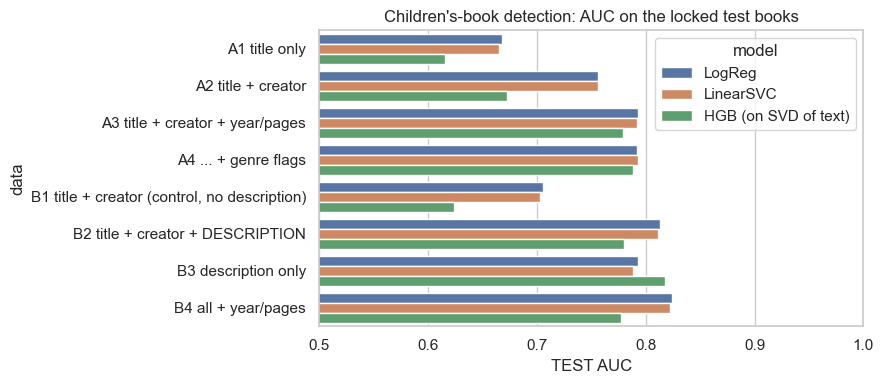

In [5]:
allres = pd.concat([resA, resB], ignore_index=True)
cols = ["data", "model", "CV AUC", "TEST AUC", "TEST accuracy", "TEST balanced acc", "TEST recall (kids found)", "TEST precision", "TEST F1", "TEST baseline acc (always no)"]
top = allres.sort_values("TEST AUC", ascending=False)[cols].head(8)
display(top.round(3))
bestA = resA.sort_values("CV AUC", ascending=False).iloc[0]; bestB = resB.sort_values("CV AUC", ascending=False).iloc[0]
print(f"best without description (by CV AUC): {bestA['data']} / {bestA['model']}  -> TEST AUC {bestA['TEST AUC']:.3f}, accuracy {bestA['TEST accuracy']:.3f}, balanced acc {bestA['TEST balanced acc']:.3f}, recall {bestA['TEST recall (kids found)']:.3f}")
print(f"best with description    (by CV AUC): {bestB['data']} / {bestB['model']}  -> TEST AUC {bestB['TEST AUC']:.3f}, accuracy {bestB['TEST accuracy']:.3f}, balanced acc {bestB['TEST balanced acc']:.3f}, recall {bestB['TEST recall (kids found)']:.3f}")
print("Your target 'above 80% accuracy' is meaningless on its own here (always-'no' = ~83%). Use balanced accuracy / AUC / recall.")
fig, ax = plt.subplots(figsize=(9, 4)); sns.barplot(data=allres, y="data", x="TEST AUC", hue="model", ax=ax); ax.set_xlim(0.5, 1); ax.set_title("Children's-book detection: AUC on the locked test books"); plt.tight_layout(); plt.show()

In [6]:
# what does the model look at? strongest words for the best description model (LogReg on all 3,152 books)
lab = "B3 description only"
pre = make_pre((), desc=True); m = LogisticRegression(max_iter=3000, C=3, class_weight="balanced").fit(pre.fit_transform(withd), withd["juvenile"])
names = np.array(pre.get_feature_names_out()); co = m.coef_[0]
print("words that point to CHILDREN:", ", ".join(n.replace("desc__", "") for n in names[np.argsort(-co)[:25]]))
print("words that point to NOT children:", ", ".join(n.replace("desc__", "") for n in names[np.argsort(co)[:25]]))
# confusion matrix and examples for the best description model on the locked test books
name = max([k for k in kept if k.startswith("B")], key=lambda k: allres[(allres.data == k)]["CV AUC"].max())
mname = allres[allres.data == name].sort_values("CV AUC", ascending=False).iloc[0]["model"]
mm, st, yt, thr, test = kept[name][mname]
pr = (st >= thr).astype(int)
print("\nbest B variant:", name, "/", mname, "| confusion matrix [rows = true no/yes, columns = predicted no/yes]:\n", confusion_matrix(yt, pr))
fn = test[(yt == 1) & (pr == 0)].head(6)[["title", "description"]]
fp = test[(yt == 0) & (pr == 1)].head(6)[["title", "description"]]
print("\nkids' books the model MISSED:"); display(fn.assign(description=fn["description"].str[:160]))
print("books it called children's but are NOT tagged juvenile (may be missing tags):"); display(fp.assign(description=fp["description"].str[:160]))

words that point to CHILDREN: accelerated, accelerated reader, mg, ages, school, page, lg, journey, way, reader, save, ages 12, order, best friend, 12, pet, mission, year, friends, guardians, help, like, monsters, abandoned, angry
words that point to NOT children: man, men, people, woman, novel, murder, left, wife, killer, human, ar ug, science, recover, john, del, verso, case, money, murdered, drawn, shadow, captain, husband, guardian, job

best B variant: B4 all + year/pages / HGB (on SVD of text) | confusion matrix [rows = true no/yes, columns = predicted no/yes]:
 [[250 104]
 [ 34  67]]

kids' books the model MISSED:


,title,description
3,The house on Hound Hill,"Soon after she, her mother, and her younger br..."
40,Attack of the lethal lizards,"On the far-off planet Reptilius, a swamp is za..."
50,The space ship under the apple tree,When Eddie Blow investigated what he thought w...
80,The secret country,Having learned from a talking cat that he and ...
88,Harry Potter and the sorcerer's stone,Rescued from the outrageous neglect of his aun...
136,Mothership,"In 2074, while attending the Hanover School fo..."


books it called children's but are NOT tagged juvenile (may be missing tags):


,title,description
1,Pack challenge [electronic resource],When Zach and his motorcycle club ride into Sa...
6,"Bound to rise : or, Harry Walton's motto","In 1870's New Hampshire, fifteen-year-old Harr..."
15,Tale of the Toa,"""In the time before time, a great being watche..."
19,The power twins,"""Previously published in England as the Power ..."
22,"Ned Feldman, space pirate","One day when Ned's parents are out, he meets C..."
29,Serenity,Mal and his crew take on a heist that promises...


## Summary and suggestions
* Read the numbers above: the honest measures are AUC, recall and balanced accuracy, not plain accuracy.
* The description is the strongest extra signal for this task (see B1 vs B2/B3 and the words list).
* Because the tag is incomplete, expect a ceiling below 100%. Ideas to push further: more descriptions (collect more books), adding the publisher or reading-level text when present, and treating "predicted kids but untagged" books as possible missing tags to review by hand.